In [ ]:
!pip install -q pytorch-fid roboflow
!git clone https://github.com/PaweekornS/underwater_sonar.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.8/195.8 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 129.9 MB/s eta 0:00:00
Cloning into 'underwater_sonar'...
remote: Enumerating objects: 4791, done.
remote: Counting objects: 100% (1168/1168), done.
remote: Compressing objects: 100% (1142/1142), done.
remote: Total 4791 (delta 60), reused 1126 (delta 26), pack-reused 3623 (from 1)
Receiving objects: 100% (4791/4791), 357.97 MiB | 18.54 MiB/s, done.
Resolving deltas: 100% (229/229), done.
Updating files: 100% (4368/4368), done.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
import cv2

from itertools import batched
from dataclasses import dataclass
from datasets import load_dataset
from tqdm.auto import tqdm

import glob
import os
import io

import math, time, random
from typing import List, Tuple, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from torchvision.utils import make_grid, save_image

device = "cuda" if torch.cuda.is_available() else "cpu"

## SPADE+GAN
- "Side-Scan Sonar Image Synthesis Based on GAN for Images in Multiple Frequencies" (Jiang et al., 2021)
- **Core ideas:** SPADE-guided generator (Pix2PixHD-style upsampling), pixel distribution predictor (μ,σ), multi-scale PatchGAN  discriminators, GAN + Feature Matching + KL losses.

### Architecture

In [ ]:
# ---------------------------
# Utils
# ---------------------------

def weights_init_normal(m: nn.Module):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1 or classname.find("Linear") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if getattr(m, "bias", None) is not None and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif classname.find("BatchNorm2d") != -1 or classname.find("InstanceNorm2d") != -1:
        if getattr(m, "weight", None) is not None and m.weight is not None:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
        if getattr(m, "bias", None) is not None and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)


def one_hot(seg: torch.Tensor, num_classes: int) -> torch.Tensor:
    """
    Convert integer HxW segmentation (0..K-1) to one-hot [B, K, H, W].
    If seg already one-hot, returns as-is.
    """
    if seg.dim() == 4 and seg.size(1) == num_classes:
        return seg
    # seg: [B,1,H,W] or [B,H,W]
    if seg.dim() == 3:
        seg = seg.unsqueeze(1)
    b, _, h, w = seg.shape
    out = torch.zeros(b, num_classes, h, w, device=seg.device, dtype=torch.float32)
    return out.scatter_(1, seg.long(), 1.0)


# ---------------------------
# SPADE Block
# ---------------------------

class SPADE(nn.Module):
    """
    SPADE: Spatially-Adaptive (DE)normalization.
    We modulate an InstanceNorm2d with gamma, beta predicted from segmentation map.
    """
    def __init__(self, norm_nc: int, label_nc: int, ks: int = 3, hidden: int = 128):
        super().__init__()
        pw = ks // 2
        self.param_free_norm = nn.InstanceNorm2d(norm_nc, affine=False, eps=1e-5)

        self.mlp_shared = nn.Sequential(
            nn.Conv2d(label_nc, hidden, kernel_size=ks, padding=pw),
            nn.ReLU(inplace=True),
        )
        self.mlp_gamma = nn.Conv2d(hidden, norm_nc, kernel_size=ks, padding=pw)
        self.mlp_beta  = nn.Conv2d(hidden, norm_nc, kernel_size=ks, padding=pw)

    def forward(self, x: torch.Tensor, seg: torch.Tensor) -> torch.Tensor:
        # seg: [B, label_nc, H, W], resize to x spatial dims if needed
        if seg.shape[-2:] != x.shape[-2:]:
            seg = F.interpolate(seg, size=x.shape[-2:], mode="nearest")
        normalized = self.param_free_norm(x)
        actv = self.mlp_shared(seg)
        gamma = self.mlp_gamma(actv)
        beta  = self.mlp_beta(actv)
        return normalized * (1 + gamma) + beta


class SPADEResBlock(nn.Module):
    """
    Simple residual block with SPADE on both convs (no spectral norm here for simplicity).
    """
    def __init__(self, fin: int, fout: int, label_nc: int):
        super().__init__()
        fmiddle = min(fin, fout)

        self.learned_shortcut = (fin != fout)
        self.spade_1 = SPADE(fin, label_nc)
        self.conv_1  = nn.Conv2d(fin, fmiddle, kernel_size=3, padding=1)

        self.spade_2 = SPADE(fmiddle, label_nc)
        self.conv_2  = nn.Conv2d(fmiddle, fout, kernel_size=3, padding=1)

        if self.learned_shortcut:
            self.spade_s = SPADE(fin, label_nc)
            self.conv_s  = nn.Conv2d(fin, fout, kernel_size=1, padding=0)

        self.relu = nn.LeakyReLU(0.2, inplace=True)

    def shortcut(self, x, seg):
        if self.learned_shortcut:
            x_s = self.spade_s(x, seg)
            x_s = self.conv_s(self.relu(x_s))
            return x_s
        return x

    def forward(self, x: torch.Tensor, seg: torch.Tensor) -> torch.Tensor:
        x_s = self.shortcut(x, seg)

        dx = self.spade_1(x, seg)
        dx = self.conv_1(self.relu(dx))

        dx = self.spade_2(dx, seg)
        dx = self.conv_2(self.relu(dx))

        return x_s + dx


# ---------------------------
# Pixel Distribution Predictor (μ, logσ)
# ---------------------------

class PixelDistributionPredictor(nn.Module):
    """
    CNN that extracts pixel/style stats and predicts mean, logvar for latent z.
    """
    def __init__(self, in_nc: int = 1, z_dim: int = 256):  # SSS often grayscale -> in_nc=1; change if RGB=3
        super().__init__()
        nf = 64
        self.features = nn.Sequential(
            nn.Conv2d(in_nc, nf, 3, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf, nf*2, 3, 2, 1), nn.BatchNorm2d(nf*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf*2, nf*4, 3, 2, 1), nn.BatchNorm2d(nf*4), nn.LeakyReLU(0.2, True),
            nn.Conv2d(nf*4, nf*8, 3, 2, 1), nn.BatchNorm2d(nf*8), nn.LeakyReLU(0.2, True),
            nn.AdaptiveAvgPool2d((1,1)),
        )
        self.mu     = nn.Linear(nf*8, z_dim)
        self.logvar = nn.Linear(nf*8, z_dim)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        b = x.size(0)
        f = self.features(x).view(b, -1)
        mu = self.mu(f)
        logvar = self.logvar(f)
        return mu, logvar


# ---------------------------
# Generator (Pix2pixHD-like upsampling + SPADE)
# ---------------------------

class SPADEGenerator(nn.Module):
    """
    Start from latent z, project to small spatial map, then upsample with SPADEResBlocks to 256x256.
    """
    def __init__(self, z_dim: int, out_nc: int, label_nc: int, ngf: int = 64, out_size: int = 256):
        super().__init__()
        self.z_dim = z_dim
        self.label_nc = label_nc
        self.out_size = out_size

        self.fc = nn.Linear(z_dim, 16*ngf*4*4)  # start at 4x4 with 16*ngf channels

        ch = 16 * ngf
        self.block_4  = SPADEResBlock(ch, 8*ngf,  label_nc)
        self.block_8  = SPADEResBlock(8*ngf,  8*ngf,  label_nc)
        self.block_16 = SPADEResBlock(8*ngf,  4*ngf,  label_nc)
        self.block_32 = SPADEResBlock(4*ngf,  2*ngf,  label_nc)
        self.block_64 = SPADEResBlock(2*ngf,  1*ngf,  label_nc)
        self.block_128= SPADEResBlock(1*ngf,  1*ngf//2, label_nc)
        self.block_256= SPADEResBlock(1*ngf//2, 1*ngf//4, label_nc)

        self.to_rgb = nn.Sequential(
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ngf//4, out_nc, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, z: torch.Tensor, seg: torch.Tensor) -> torch.Tensor:
        """
        z: [B, z_dim]
        seg: [B, label_nc, H, W] (will be down/up-sampled internally)
        output: [B, out_nc, 256, 256] by default
        """
        b = z.size(0)
        x = self.fc(z).view(b, -1, 4, 4)

        # Upsample progressively to reach out_size
        def up(x): return F.interpolate(x, scale_factor=2, mode="nearest")

        x = self.block_4(x, seg)     # 4x4 -> 4x4
        x = up(x)
        x = self.block_8(x, seg)     # 8x8
        x = up(x)
        x = self.block_16(x, seg)    # 16x16
        x = up(x)
        x = self.block_32(x, seg)    # 32x32
        x = up(x)
        x = self.block_64(x, seg)    # 64x64
        x = up(x)
        x = self.block_128(x, seg)   # 128x128
        x = up(x)
        x = self.block_256(x, seg)   # 256x256

        out = self.to_rgb(x)
        return out


# ---------------------------
# PatchGAN Discriminator + Multi-scale
# ---------------------------

class NLayerDiscriminator(nn.Module):
    """
    PatchGAN: takes concatenated [image, seg_onehot] as input.
    Returns logits and intermediate features for feature matching.
    """
    def __init__(self, in_nc: int, ndf: int = 64, n_layers: int = 4):
        super().__init__()
        kw = 4
        pw = 1

        sequence = []
        # first layer (no norm)
        sequence += [
            nn.Conv2d(in_nc, ndf, kernel_size=kw, stride=2, padding=pw),
            nn.LeakyReLU(0.2, True),
        ]
        nf_mult = 1
        for n in range(1, n_layers):
            nf_prev = nf_mult
            nf_mult = min(2**n, 8)
            sequence += [
                nn.Conv2d(ndf*nf_prev, ndf*nf_mult, kernel_size=kw, stride=2, padding=pw),
                nn.InstanceNorm2d(ndf*nf_mult, affine=False, eps=1e-5),
                nn.LeakyReLU(0.2, True),
            ]
        # final convs
        sequence += [
            nn.Conv2d(ndf*nf_mult, ndf*nf_mult, kernel_size=kw, stride=1, padding=pw),
            nn.InstanceNorm2d(ndf*nf_mult, affine=False, eps=1e-5),
            nn.LeakyReLU(0.2, True),
        ]
        sequence += [nn.Conv2d(ndf*nf_mult, 1, kernel_size=kw, stride=1, padding=pw)]

        self.model = nn.Sequential(*sequence)

    def forward(self, x: torch.Tensor, return_feats: bool = True):
        feats = []
        out = x
        for layer in self.model:
            out = layer(out)
            if isinstance(layer, nn.LeakyReLU):
                feats.append(out)
        if return_feats:
            return out, feats
        return out


class MultiScaleDiscriminator(nn.Module):
    """
    Three discriminators at different image scales (as in Pix2PixHD).
    """
    def __init__(self, in_nc: int, num_D: int = 3, ndf: int = 64, n_layers: int = 4):
        super().__init__()
        self.num_D = num_D
        self.discriminators = nn.ModuleList([
            NLayerDiscriminator(in_nc, ndf, n_layers) for _ in range(num_D)
        ])
        self.downsample = nn.AvgPool2d(kernel_size=3, stride=2, padding=1, count_include_pad=False)

    def forward(self, x: torch.Tensor) -> List[Tuple[torch.Tensor, List[torch.Tensor]]]:
        results = []
        inp = x
        for i in range(self.num_D):
            out = self.discriminators[i](inp, return_feats=True)
            results.append(out)
            if i != self.num_D - 1:
                inp = self.downsample(inp)
        return results


# ---------------------------
# Losses: LSGAN, Feature Matching, KL
# ---------------------------

class GANLoss(nn.Module):
    """
    Least-Squares GAN loss (as used in Pix2pixHD).
    """
    def __init__(self):
        super().__init__()
        self.loss = nn.MSELoss()

    def _target(self, preds: torch.Tensor, is_real: bool) -> torch.Tensor:
        return torch.ones_like(preds) if is_real else torch.zeros_like(preds)

    def d_loss(self, pred_real: torch.Tensor, pred_fake: torch.Tensor) -> torch.Tensor:
        loss_real = self.loss(pred_real, self._target(pred_real, True))
        loss_fake = self.loss(pred_fake, self._target(pred_fake, False))
        return 0.5 * (loss_real + loss_fake)

    def g_loss(self, pred_fake: torch.Tensor) -> torch.Tensor:
        return self.loss(pred_fake, self._target(pred_fake, True))


def feature_matching_loss(feats_real: List[torch.Tensor],
                          feats_fake: List[torch.Tensor]) -> torch.Tensor:
    """
    L1 feature matching across layers.
    """
    loss = 0.0
    for fr, ff in zip(feats_real, feats_fake):
        loss += F.l1_loss(ff, fr.detach())
    return loss


def kl_divergence_loss(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """
    KL( N(mu, sigma^2) || N(0, I) ) = -0.5 * sum(1 + logvar - mu^2 - exp(logvar))
    averaged over batch.
    """
    return -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())


# ---------------------------
# Full Model Wrapper
# ---------------------------

class SSS_SPADE_GAN(nn.Module):
    def __init__(
        self,
        img_nc: int = 1,          # sonar grayscale by default
        seg_nc: int = 3,          # e.g., seabed / highlight / shadow
        z_dim: int = 256,
        ngf: int = 64,
        ndf: int = 64,
        num_D: int = 3,
        n_layers_D: int = 4,
        img_size: int = 256,
        fm_lambda: float = 10.0   # feature matching weight (λ)
    ):
        super().__init__()
        self.z_dim = z_dim
        self.seg_nc = seg_nc
        self.img_nc = img_nc
        self.fm_lambda = fm_lambda

        # Modules
        self.pdp = PixelDistributionPredictor(in_nc=img_nc, z_dim=z_dim)
        self.netG = SPADEGenerator(z_dim=z_dim, out_nc=img_nc, label_nc=seg_nc, ngf=ngf, out_size=img_size)
        # Discriminators take concat([image, seg_onehot]) as channels
        self.netD = MultiScaleDiscriminator(in_nc=img_nc + seg_nc, num_D=num_D, ndf=ndf, n_layers=n_layers_D)

        # Losses
        self.gan_loss = GANLoss()

        # Init
        self.apply(weights_init_normal)

    def sample_z(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward_G(self, seg_oh: torch.Tensor, real_img: Optional[torch.Tensor] = None) -> Dict[str, torch.Tensor]:
        """
        If real_img provided: use PDP to sample z ~ N(μ, σ) from real image (training).
        Else: z ~ N(0, I) (inference).
        """
        if real_img is not None:
            mu, logvar = self.pdp(real_img)
            z = self.sample_z(mu, logvar)
            fake = self.netG(z, seg_oh)
            return {"fake": fake, "mu": mu, "logvar": logvar}
        else:
            z = torch.randn(seg_oh.size(0), self.z_dim, device=seg_oh.device)
            fake = self.netG(z, seg_oh)
            return {"fake": fake}

    def D_forward(self, img: torch.Tensor, seg_oh: torch.Tensor):
        x = torch.cat([img, seg_oh], dim=1)
        return self.netD(x)

    def compute_D_loss(self, real_img: torch.Tensor, fake_img: torch.Tensor, seg_oh: torch.Tensor) -> torch.Tensor:
        d_out_real = self.D_forward(real_img, seg_oh)
        d_out_fake = self.D_forward(fake_img.detach(), seg_oh)

        loss = 0.0
        for (pred_r, _feats_r), (pred_f, _feats_f) in zip(d_out_real, d_out_fake):
            loss += self.gan_loss.d_loss(pred_r, pred_f)
        return loss / len(d_out_real)

    def compute_G_loss(self, real_img: torch.Tensor, fake_img: torch.Tensor, seg_oh: torch.Tensor) -> Tuple[torch.Tensor, Dict[str, float]]:
        d_out_fake = self.D_forward(fake_img, seg_oh)
        d_out_real = self.D_forward(real_img, seg_oh)

        loss_g_gan = 0.0
        loss_g_fm  = 0.0
        for (pred_r, feats_r), (pred_f, feats_f) in zip(d_out_real, d_out_fake):
            loss_g_gan += self.gan_loss.g_loss(pred_f)
            loss_g_fm  += feature_matching_loss(feats_r, feats_f)

        loss_g_gan /= len(d_out_fake)
        loss_g_fm  /= len(d_out_fake)

        loss = loss_g_gan + self.fm_lambda * loss_g_fm
        logs = {"G_gan": float(loss_g_gan.item()), "G_fm": float(loss_g_fm.item())}
        return loss, logs


# ---------------------------
# Training Skeleton
# ---------------------------

def train_one_epoch(
    model: SSS_SPADE_GAN,
    loader: DataLoader,
    opt_G: torch.optim.Optimizer,
    opt_D: torch.optim.Optimizer,
    device: torch.device,
    num_classes: int,
    kl_lambda: float = 1.0,
    grad_accum_steps: int = 1
):
    model.train()
    running = {"D":0.0, "G":0.0, "KL":0.0, "G_gan":0.0, "G_fm":0.0}
    for step, batch in enumerate(loader, 1):
        # Expect batch dict: {"image": [B, C, H, W], "seg": [B,H,W] or [B,K,H,W]}
        real = batch["image"].to(device)           # normalized to [-1,1]
        seg  = batch["segment"].to(device)
        seg_oh = one_hot(seg, num_classes)

        # ---- G forward
        outG = model.forward_G(seg_oh, real_img=real)
        fake = outG["fake"]
        mu, logvar = outG["mu"], outG["logvar"]

        # ---- D update
        opt_D.zero_grad(set_to_none=True)
        d_loss = model.compute_D_loss(real, fake, seg_oh)
        (d_loss / grad_accum_steps).backward()
        if step % grad_accum_steps == 0:
            opt_D.step()

        # ---- G update
        opt_G.zero_grad(set_to_none=True)
        g_loss, g_logs = model.compute_G_loss(real, fake, seg_oh)
        kl = kl_divergence_loss(mu, logvar) * kl_lambda
        total_g = g_loss + kl
        (total_g / grad_accum_steps).backward()
        if step % grad_accum_steps == 0:
            opt_G.step()

        running["D"] += d_loss.item()
        running["G"] += g_loss.item()
        running["KL"]+= kl.item()
        running["G_gan"] += g_logs["G_gan"]
        running["G_fm"]  += g_logs["G_fm"]

    n = len(loader)
    for k in running:
        running[k] /= max(n, 1)
    return running


@torch.no_grad()
def sample_inference(
    model: SSS_SPADE_GAN,
    seg_batch: torch.Tensor,        # [B, K, H, W] or [B,1,H,W] int labels
    num_classes: int,
    device: torch.device
) -> torch.Tensor:
    model.eval()
    seg_oh = one_hot(seg_batch.to(device), num_classes)
    out = model.forward_G(seg_oh, real_img=None)
    return out["fake"]  # [-1,1]

### Main pipeline

In [ ]:
segment_files = np.sort(glob.glob("/content/underwater_sonar/data/klsg_prep/masked/*/*.png"))

df = []
for f in segment_files:
    data = {"image": f.replace("masked", "resized"), "segment": f}
    df.append(data)
df = pd.DataFrame(df)
df['class'] = df['segment'].apply(lambda x: x.split("/")[-2])

sample_df = df.groupby('class').apply(lambda x: x.sample(60, replace=True)).reset_index(drop=True)
df['class'].value_counts()

/tmp/ipykernel_29492/1995039742.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df = df.groupby('class').apply(lambda x: x.sample(60, replace=True)).reset_index(drop=True)


,count
class,
ship,434
victim,181
plane,59
fish,15


In [ ]:
def refine_mask(segment_file):
    mask = cv2.imread(segment_file, 0)
    mask[ mask < 200 ] = 0
    mask[mask >= 200] = 1
    return mask

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((256, 256)),
    transforms.ConvertImageDtype(torch.float),
    transforms.Normalize((0.5,), (0.5,))
])

class ImageDataset(Dataset):
    def __init__(self, df):
        self.images = df['image'].tolist()
        self.segment = df['segment'].tolist()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx])
        seg = refine_mask(self.segment[idx])
        if transform:
            img = transform(img)
        return {"image": img, "segment": seg}

ds = ImageDataset(sample_df)
train_loader = DataLoader(ds, batch_size=32, shuffle=True)

for inputs in train_loader:
    print(inputs['image'].shape)
    break

torch.Size([32, 1, 256, 256])


In [ ]:
def sample_grid(model, train_loader):
    os.makedirs("inference_results", exist_ok=True)
    model.eval()
    with torch.no_grad():
        vis_batch = next(iter(train_loader))
        vis_seg = vis_batch["segment"][:8] # Take up to 8 samples
        fake_samples = sample_inference(model, vis_seg, 3, device)

        grid = make_grid(fake_samples, nrow=4, normalize=True, value_range=(-1, 1))
        save_image(grid, f"inference_results/epoch_{epoch}.png")

    model.train()

model = SSS_SPADE_GAN(
    img_nc=1,
    seg_nc=3,
    z_dim=32,
    fm_lambda=2.0
).to(device)

opt_G = torch.optim.Adam(
    list(model.netG.parameters()) + list(model.pdp.parameters()),
    lr=2e-4, betas=(0.5, 0.999)
)
opt_D = torch.optim.Adam(model.netD.parameters(), lr=2e-4, betas=(0.5, 0.999))

epochs = 200
for epoch in tqdm(range(1, epochs+1)):
    logs = train_one_epoch(
        model, train_loader, opt_G, opt_D, device,
        num_classes=3, kl_lambda=1.0
    )
    if epoch % 10 == 0:
        print(
            f"Epoch {epoch} | D: {logs['D']:.3f} | G: {logs['G']:.3f}",
            f"KL: {logs['KL']:.3f} | G_gan: {logs['G_gan']:.3f} | G_fm: {logs['G_fm']:.3f}"
        )
        sample_grid(model, train_loader)

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch 10 | D: 0.184 | G: 3.854 KL: 0.013 | G_gan: 0.886 | G_fm: 1.484
Epoch 20 | D: 0.183 | G: 3.848 KL: 0.008 | G_gan: 1.020 | G_fm: 1.414
Epoch 30 | D: 0.124 | G: 3.875 KL: 0.005 | G_gan: 0.972 | G_fm: 1.451
Epoch 40 | D: 0.108 | G: 3.623 KL: 0.001 | G_gan: 0.905 | G_fm: 1.359
Epoch 50 | D: 0.113 | G: 3.696 KL: 0.000 | G_gan: 0.924 | G_fm: 1.386
Epoch 60 | D: 0.125 | G: 3.427 KL: 0.000 | G_gan: 0.855 | G_fm: 1.286
Epoch 70 | D: 0.133 | G: 3.278 KL: 0.000 | G_gan: 0.885 | G_fm: 1.197
Epoch 80 | D: 0.096 | G: 3.086 KL: 0.000 | G_gan: 0.806 | G_fm: 1.140
Epoch 90 | D: 0.109 | G: 3.084 KL: 0.000 | G_gan: 0.883 | G_fm: 1.101
Epoch 100 | D: 0.077 | G: 2.911 KL: 0.000 | G_gan: 0.846 | G_fm: 1.033
Epoch 110 | D: 0.119 | G: 2.883 KL: 0.000 | G_gan: 0.859 | G_fm: 1.012
Epoch 120 | D: 0.132 | G: 2.846 KL: 0.000 | G_gan: 0.857 | G_fm: 0.994
Epoch 130 | D: 0.095 | G: 2.759 KL: 0.000 | G_gan: 0.788 | G_fm: 0.985
Epoch 140 | D: 2.785 | G: 5.564 KL: 0.000 | G_gan: 3.357 | G_fm: 1.103
Epoch 150 | D: 

**Inference**

0it [00:00, ?it/s]

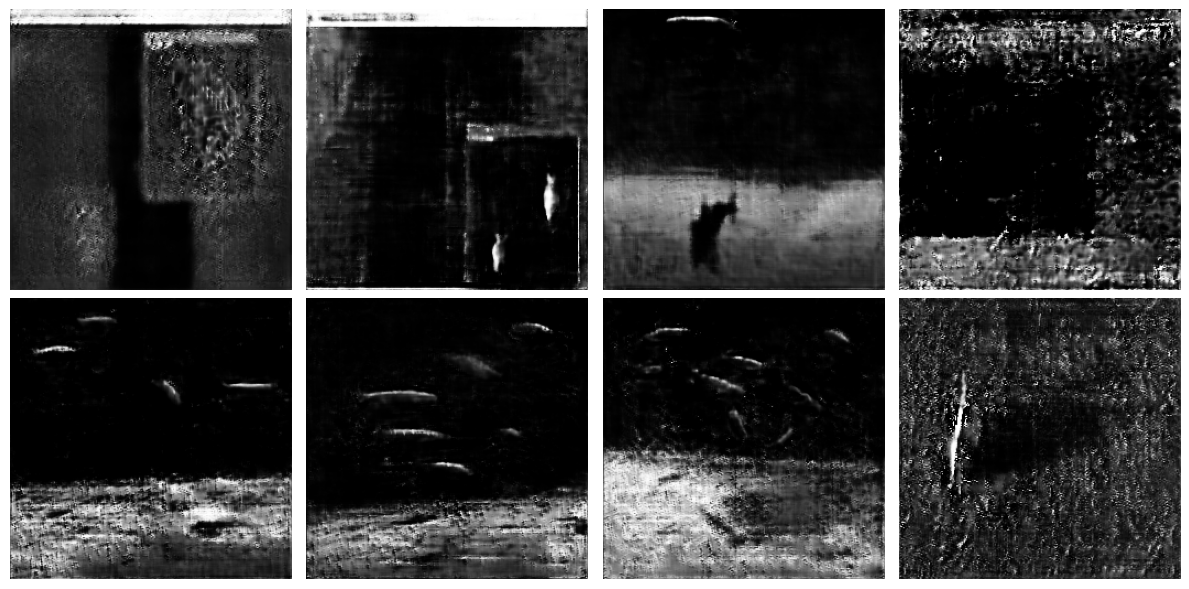

In [ ]:
val_segment = [ refine_mask(f) for f in segment_files ]

# Inference example (given a segmentation map)
generated = []
for batch in batched(val_segment, 32):
    fake = sample_inference(model, torch.tensor(np.array(batch)), 3, device)
    generated.extend(fake)

# plot result
row, col = 2, 4
plt.subplots(row, col, figsize=(12, 6))
for i, img in tqdm  (enumerate(generated[:row*col])):
    plt.subplot(row, col, i+1)
    plt.imshow(img.permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5, cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

**Evaluation**

In [ ]:
os.makedirs("/content/eval_images/fake", exist_ok=True)
os.makedirs("/content/eval_images/real", exist_ok=True)

!cp /content/underwater_sonar/data/klsg_prep/resized/*/* /content/eval_images/real/

# Convert fake images from [-1, 1] to [0, 255] and save
for i, img_tensor in tqdm(enumerate(generated), total=len(generated)):
    img = img_tensor.squeeze(0).cpu().numpy() # Shape becomes (H, W)
    img = (img * 0.5 + 0.5) * 255
    img = img.astype(np.uint8)
    fname = os.path.join("eval_images/fake", f"fake_{i+1:04d}.png")
    img = cv2.resize(img, (256, 256))
    cv2.imwrite(fname, img)

0it [00:00, ?it/s]

In [ ]:
import sys
sys.path.append("./underwater_sonar/synthetic")

from eval import calculate_metrics

# call evaluation
fid_score, ssim_score, psnr_score = calculate_metrics(
    "/content/eval_images/real", # Directory of real images
    "/content/eval_images/fake", # List of generated image tensors
    device=device,
    batch_size=32
)

print(f"FID: {fid_score:.4f}")
print(f"SSIM: {ssim_score:.4f}")
print(f"PSNR: {psnr_score:.4f}")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 525MB/s]
100%|██████████| 22/22 [00:01<00:00, 12.74it/s]


FID: 180.8353
SSIM: 0.0908
PSNR: 11.7786


## cGAN

In [ ]:
class_map = {
    'airplane': 0,
    'shipwreck': 1,
    'victim': 2,
    'fish': 3,
    'other': 4,
}

ds = load_dataset("PaweekornSora/sonar-diffusion-dataset", split="train")
train_df = ds.to_pandas()

cropped_img_df = train_df[ train_df['text'].apply(lambda x: "cropped" in x)  ].reset_index(drop=True)
cropped_img_df['class'] = cropped_img_df['text'].apply(lambda x: x.split()[-1])
cropped_img_df['class_id'] = cropped_img_df['text'].apply(lambda x: class_map[x.split()[-1]])
cropped_img_df.head()

,image,text,class,class_id
0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,a cropped side-scan sonar image of shipwreck,shipwreck,1
1,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,a cropped side-scan sonar image of shipwreck,shipwreck,1
2,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,a cropped side-scan sonar image of airplane,airplane,0
3,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,a cropped side-scan sonar image of airplane,airplane,0
4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,a cropped side-scan sonar image of shipwreck,shipwreck,1


In [ ]:
sample_df = cropped_img_df.groupby('class').apply(lambda x: x.sample(100, replace=True) if len(x) > 100 else x).reset_index(drop=True)
sample_df['class'].value_counts()

/tmp/ipykernel_8630/3429103880.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df = cropped_img_df.groupby('class').apply(lambda x: x.sample(100, replace=True) if len(x) > 100 else x).reset_index(drop=True)


,count
class,
victim,100
shipwreck,100
airplane,98
other,47
fish,16


### Dataset

In [ ]:
class SonarDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return self.dataframe.shape[0]

    def __getitem__(self, idx):
        # 1. Extract and process image bytes
        img_bytes = self.dataframe.loc[idx, 'image']['bytes']
        image = Image.open(io.BytesIO(img_bytes)).convert("L")

        # 2. Apply transformations
        if self.transform:
            image = self.transform(image)

        # 3. Get label
        label = self.dataframe.loc[idx, 'class_id']

        return image, label

# --- Configuration ---
NUM_EPOCHS = 500
BATCH_SIZE = 32
LATENT_DIM = 128
NUM_CLASSES = 3
LEARNING_RATE = 0.0002
CHECKPOINT_DIR = "checkpoints"
IMG_SIZE = 64

# --- Dataset ---
transform_pipeline = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# train only victim, shipwreck, and airplane
filtered_df = sample_df[sample_df['class'].isin(['shipwreck', 'airplane', 'victim']) ].reset_index(drop=True)
train_dataset = SonarDataset(filtered_df, transform=transform_pipeline)

# Apply to DataLoader
dataloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
)

for inputs, labels in dataloader:
    print(inputs[0].shape, labels[0])
    break

torch.Size([1, 64, 64]) tensor(0)


In [ ]:
# @title Architecture

img_channels = 1
flat_dim = img_channels * IMG_SIZE * IMG_SIZE

class Generator(nn.Module):
    def __init__(self, latent_dim, num_classes, img_channels=img_channels):
        super(Generator, self).__init__()

        # Embed the class label to match the latent space dimension
        self.label_emb = nn.Embedding(num_classes, latent_dim)

        self.init_size = IMG_SIZE // 4 # For a 64x64 output. (Use 32 for a 128x128 output)

        # Project combined latent vector + label into a spatial tensor
        self.l1 = nn.Sequential(nn.Linear(latent_dim * 2, 128 * self.init_size ** 2))

        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128),

            # Upsample 1: 16x16 -> 32x32
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128, 0.8),
            nn.LeakyReLU(0.2, inplace=True),

            # Upsample 2: 32x32 -> 64x64
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64, 0.8),
            nn.LeakyReLU(0.2, inplace=True),

            # Final output layer
            nn.Conv2d(64, img_channels, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, z, labels):
        # Embed label and concatenate with latent noise
        c = self.label_emb(labels)
        gen_input = torch.cat((z, c), dim=-1) # Shape: (batch, latent_dim * 2)

        out = self.l1(gen_input)
        out = out.view(out.shape[0], 128, self.init_size, self.init_size) # Reshape to spatial
        img = self.conv_blocks(out)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes, img_channels=img_channels, img_size=IMG_SIZE):
        super(Discriminator, self).__init__()

        # We process the label so it can be concatenated as an extra image channel
        self.label_emb = nn.Embedding(num_classes, 50)
        self.label_proj = nn.Linear(50, img_size * img_size)

        # Input channels = image_channels + 1 (for the label map)
        self.model = nn.Sequential(
            # 64x64 -> 32x32
            nn.Conv2d(img_channels + 1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.3), # Dropout is crucial for sonar speckle noise

            # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.3),

            # 16x16 -> 8x8
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.3),

            # 8x8 -> 4x4
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.3),
        )

        # Calculate downsampled size (64 / 2^4 = 4)
        ds_size = img_size // 16
        self.adv_layer = nn.Sequential(
            nn.Linear(512 * ds_size ** 2, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        # Create a spatial map out of the label to concatenate with the image
        c = self.label_proj(self.label_emb(labels))
        c = c.view(c.shape[0], 1, img.size(2), img.size(3))

        d_in = torch.cat((img, c), dim=1) # Shape: (batch, 2, H, W)

        out = self.model(d_in)
        out = out.view(out.shape[0], -1) # Flatten for final classification
        return self.adv_layer(out)

### Training loop

In [ ]:
# --- Initialize Models ---
generator = Generator(LATENT_DIM, NUM_CLASSES).to(device)
discriminator = Discriminator(NUM_CLASSES).to(device)

optimizer_G = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
criterion = nn.BCELoss()

# --- Helper: Save Checkpoints ---
def save_checkpoint(epoch, gen, disc, opt_g, opt_d):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    torch.save({
        'epoch': epoch,
        'gen_state_dict': gen.state_dict(),
        'disc_state_dict': disc.state_dict(),
        'opt_g_state_dict': opt_g.state_dict(),
        'opt_d_state_dict': opt_d.state_dict(),
    }, f"{CHECKPOINT_DIR}/model_epoch_{epoch}.pth")

# --- Helper: visualization ---
def visualize_progress(epoch, generator, device, latent_dim, num_classes, output_dir="results"):
    os.makedirs(output_dir, exist_ok=True)
    generator.eval()

    with torch.no_grad():
        # Generate images for each class
        z = torch.randn(num_classes, latent_dim).to(device)
        labels = torch.arange(num_classes).to(device)

        sample_imgs = generator(z, labels)

        save_image(sample_imgs, f"{output_dir}/epoch_{epoch}.png",
                   nrow=5, normalize=True, value_range=(-1, 1))

    generator.train()

# --- Training Loop ---
def train(dataloader):
    generator.train()
    discriminator.train()

    for epoch in tqdm(range(NUM_EPOCHS), desc="Epoch"):
        total_g_loss = 0
        total_d_loss = 0

        for real_imgs, labels in dataloader:
            batch_size = real_imgs.size(0)
            real_imgs = real_imgs.to(device)
            labels = labels.to(device).long() # Ensure labels are Long for Embedding

            # --- 1. Train Discriminator ---
            optimizer_D.zero_grad()

            real_y = torch.full((batch_size, 1), 0.9, device=device)
            fake_y = torch.zeros(batch_size, 1, device=device)

            # Loss on Real Images
            d_out_real = discriminator(real_imgs, labels)
            d_loss_real = criterion(d_out_real, real_y)

            # Generate Fake Images
            z = torch.randn(batch_size, LATENT_DIM, device=device)
            gen_labels = torch.randint(0, NUM_CLASSES, (batch_size,), device=device)

            fake_imgs = generator(z, gen_labels)

            # Loss on Fake Images
            d_out_fake = discriminator(fake_imgs.detach(), gen_labels)
            d_loss_fake = criterion(d_out_fake, fake_y)

            d_loss = d_loss_real + d_loss_fake
            d_loss.backward()
            optimizer_D.step()

            # --- 2. Train Generator ---
            optimizer_G.zero_grad()

            g_loss = criterion(discriminator(fake_imgs, gen_labels), torch.ones(batch_size, 1, device=device))

            g_loss.backward()
            optimizer_G.step()

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()

        avg_d_loss = total_d_loss / len(dataloader)
        avg_g_loss = total_g_loss / len(dataloader)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | D Loss: {avg_d_loss:.4f} | G Loss: {avg_g_loss:.4f}")
            visualize_progress(epoch + 1, generator, device, LATENT_DIM, NUM_CLASSES)

        if (epoch + 1) % 50 == 0:
            save_checkpoint(epoch + 1, generator, discriminator, optimizer_G, optimizer_D)

if __name__ == "__main__":
    train(dataloader)

Epoch:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch [10/500] | D Loss: 1.0173 | G Loss: 1.7626
Epoch [20/500] | D Loss: 1.2689 | G Loss: 1.7110
Epoch [30/500] | D Loss: 0.8107 | G Loss: 3.1842
Epoch [40/500] | D Loss: 0.4403 | G Loss: 3.6474
Epoch [50/500] | D Loss: 0.3816 | G Loss: 4.3063
Epoch [60/500] | D Loss: 0.3642 | G Loss: 4.9389
Epoch [70/500] | D Loss: 0.3582 | G Loss: 5.2677
Epoch [80/500] | D Loss: 0.3544 | G Loss: 5.3703
Epoch [90/500] | D Loss: 0.3540 | G Loss: 5.7688
Epoch [100/500] | D Loss: 0.3498 | G Loss: 5.5654
Epoch [110/500] | D Loss: 0.3524 | G Loss: 5.8206
Epoch [120/500] | D Loss: 0.3466 | G Loss: 6.2094
Epoch [130/500] | D Loss: 0.3528 | G Loss: 5.7903
Epoch [140/500] | D Loss: 0.3477 | G Loss: 5.8386
Epoch [150/500] | D Loss: 0.3453 | G Loss: 6.4952
Epoch [160/500] | D Loss: 0.3459 | G Loss: 6.1683
Epoch [170/500] | D Loss: 0.3397 | G Loss: 6.6153
Epoch [180/500] | D Loss: 0.3412 | G Loss: 6.5030
Epoch [190/500] | D Loss: 0.3371 | G Loss: 6.8366
Epoch [200/500] | D Loss: 0.3486 | G Loss: 5.7731
Epoch [21

### Inference

In [ ]:
def inference(model_path, class_id, num_images=1):
    # 1. Initialize model structure
    gen = Generator(LATENT_DIM, NUM_CLASSES).to(device)

    # 2. Load weights
    checkpoint = torch.load(model_path, map_location=device)
    gen.load_state_dict(checkpoint['gen_state_dict'])
    gen.eval()

    # 3. Generate
    with torch.no_grad():
        z = torch.randn(num_images, LATENT_DIM).to(device)
        label_vec = torch.zeros(num_images, NUM_CLASSES).to(device)
        label_vec[:, class_id] = 1 # Set specific class

        generated_imgs = gen(z, label_vec)

    return generated_imgs